<a href="https://colab.research.google.com/github/iles-mcgill/EXSU500-Paediatric-HGGs-AI/blob/baseline-rf/notebooks/03_baseline_and_random_forest.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Mounted at /content/drive
257 patients
Counter({'seg.nii.gz': 257, 't1n.nii.gz': 257, 't1c.nii.gz': 257, 't2f.nii.gz': 257, 't2w.nii.gz': 257})
Scan size: (240, 240, 155) | voxel size (mm): (1.0, 1.0, 1.0)
Label numbers in the mask: [0 1 2 3 4]


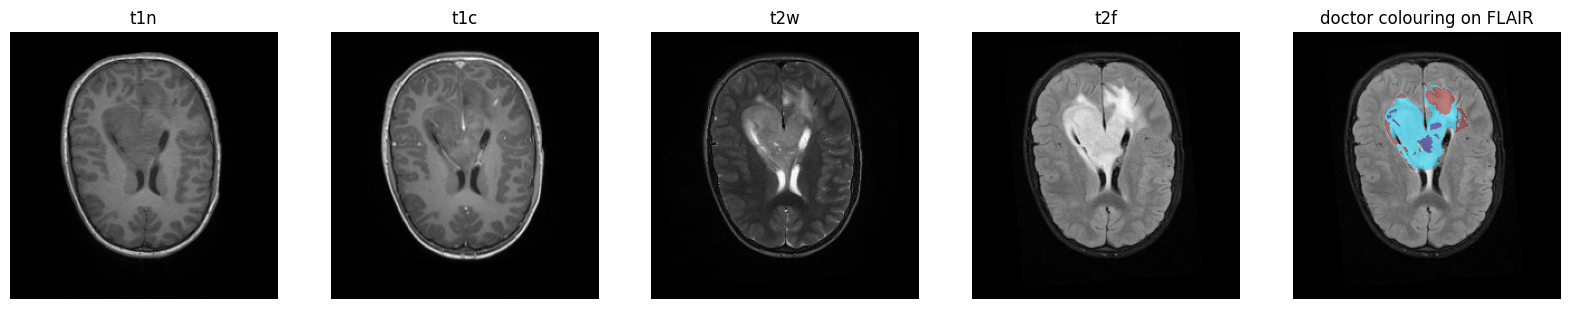

In [ ]:
# CELL 1: setup, check the data, look at one patient
from google.colab import drive
drive.mount('/content/drive')

!pip install -q nibabel
import os, glob, json, random
from collections import Counter
import numpy as np
import pandas as pd
import nibabel as nib
import matplotlib.pyplot as plt
import joblib
from scipy import ndimage

DATA_DIR = '/content/drive/MyDrive/BraTS-PEDs-full/Training'

def find_file(case_dir, key):
    # find the one file in a patient's folder whose name contains key, e.g. 't2f' or 'seg'
    hits = glob.glob(os.path.join(case_dir, f'*{key}*.nii*'))
    if len(hits) != 1:
        raise FileNotFoundError(f'Expected 1 file containing {key} in {case_dir}, found {len(hits)}')
    return hits[0]

def load_case(case_dir):
    # load one patient's 4 scans and the doctor's mask
    seqs = {}
    for key in ['t1n', 't1c', 't2w', 't2f']:
        seqs[key] = nib.load(find_file(case_dir, key)).get_fdata(dtype=np.float32)
    seg_img = nib.load(find_file(case_dir, 'seg'))
    seg = np.rint(np.asarray(seg_img.dataobj)).astype(np.uint8)
    spacing = tuple(float(s) for s in seg_img.header.get_zooms()[:3])
    return seqs, seg, spacing

# check the dataset is complete
patients = sorted(p for p in os.listdir(DATA_DIR) if p.startswith('BraTS'))
all_files = glob.glob(os.path.join(DATA_DIR, '*', '*.nii*'))
print(len(patients), 'patients')
print(Counter(f.split('-')[-1] for f in all_files))   # want 257 of each

# look at one patient
seqs, seg, spacing = load_case(os.path.join(DATA_DIR, patients[0]))
print('Scan size:', seqs['t2f'].shape, '| voxel size (mm):', spacing)
print('Label numbers in the mask:', np.unique(seg))
z = int(np.argmax((seg > 0).sum(axis=(0, 1))))
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for ax, key in zip(axes[:4], ['t1n', 't1c', 't2w', 't2f']):
    ax.imshow(np.rot90(seqs[key][:, :, z]), cmap='gray')
    ax.set_title(key)
    ax.axis('off')
axes[4].imshow(np.rot90(seqs['t2f'][:, :, z]), cmap='gray')
mask = np.ma.masked_where(seg[:, :, z] == 0, seg[:, :, z])
axes[4].imshow(np.rot90(mask), cmap='jet', alpha=0.5, vmin=1, vmax=4)
axes[4].set_title('doctor colouring on FLAIR')
axes[4].axis('off')
plt.show()

In [ ]:
# CELL 2: scoring code (Dice and HD95) and tests
MAX_HD95 = 373.13   # BraTS maximum penalty: the diagonal of a 240 x 240 x 155 mm volume

def region_masks(seg):
    # turn a label map (0-4) into the regions we score
    return {
        'WT': seg > 0,                    # whole tumour = all labels
        'TC': np.isin(seg, [1, 2, 3]),    # tumour core = everything except swelling
        'ET': seg == 1, 'NET': seg == 2, 'CC': seg == 3, 'ED': seg == 4,
    }

def dice(pred, ref):
    pred, ref = pred.astype(bool), ref.astype(bool)
    if not pred.any() and not ref.any():
        return 1.0                        # BraTS rule: both empty = correct
    return 2.0 * np.logical_and(pred, ref).sum() / (pred.sum() + ref.sum())

def surface(mask):
    # the outer layer of voxels of a shape
    return mask & ~ndimage.binary_erosion(mask)

def hd95(pred, ref, spacing=(1.0, 1.0, 1.0)):
    pred, ref = pred.astype(bool), ref.astype(bool)
    if not pred.any() and not ref.any():
        return 0.0                        # BraTS rule: both empty = correct
    if not pred.any() or not ref.any():
        return MAX_HD95                   # BraTS rule: one empty = maximum penalty
    sp, sr = surface(pred), surface(ref)
    dist_to_ref = ndimage.distance_transform_edt(~sr, sampling=spacing)
    dist_to_pred = ndimage.distance_transform_edt(~sp, sampling=spacing)
    distances = np.concatenate([dist_to_ref[sp], dist_to_pred[sr]])
    return float(np.percentile(distances, 95))

def score_case(pred_seg, ref_seg, spacing, regions=None):
    # score one patient; regions=None means all six regions
    p, r = region_masks(pred_seg), region_masks(ref_seg)
    out = {'ref_volume_WT_cm3': float(r['WT'].sum() * np.prod(spacing) / 1000)}
    for name in (regions or list(r)):
        out[f'dice_{name}'] = dice(p[name], r[name])
        out[f'hd95_{name}'] = hd95(p[name], r[name], spacing)
        out[f'present_{name}'] = bool(r[name].any())
    return out

# TEST 1: fake shapes
a = np.zeros((10, 10, 10), bool); a[2:5, 2:5, 2:5] = True    # a small cube
b = np.zeros((10, 10, 10), bool)                              # nothing
c = np.zeros((10, 10, 10), bool); c[3:6, 2:5, 2:5] = True    # the cube moved by 1 voxel
print(dice(a, a), hd95(a, a))    # should print: 1.0 0.0
print(dice(b, b), hd95(b, b))    # should print: 1.0 0.0
print(dice(a, b), hd95(a, b))    # should print: 0.0 373.13
print(round(dice(a, c), 3))      # should print: 0.667

# TEST 2: the doctor's colouring compared with itself must be perfect
print(score_case(seg, seg, spacing))   # every dice_ = 1.0, every hd95_ = 0.0

1.0 0.0
1.0 0.0
0.0 373.13
0.667
{'ref_volume_WT_cm3': 128.667, 'dice_WT': np.float64(1.0), 'hd95_WT': 0.0, 'present_WT': True, 'dice_TC': np.float64(1.0), 'hd95_TC': 0.0, 'present_TC': True, 'dice_ET': np.float64(1.0), 'hd95_ET': 0.0, 'present_ET': True, 'dice_NET': np.float64(1.0), 'hd95_NET': 0.0, 'present_NET': True, 'dice_CC': np.float64(1.0), 'hd95_CC': 0.0, 'present_CC': True, 'dice_ED': np.float64(1.0), 'hd95_ED': 0.0, 'present_ED': True}


In [ ]:
# CELL 3: download Ansar's patient split files from GitHub (his branch, PR #1)
import requests

REPO = 'iles-mcgill/EXSU500-Paediatric-HGGs-AI'
BRANCH = 'ansartlemussov/dataset-attribution-safeguards'
api = f'https://api.github.com/repos/{REPO}/contents/splits?ref={BRANCH}'

os.makedirs('splits', exist_ok=True)
for item in requests.get(api).json():
    if item['type'] == 'file':
        text = requests.get(item['download_url']).text
        with open(os.path.join('splits', item['name']), 'w') as f:
            f.write(text)
        lines = text.strip().splitlines()
        print(f"--- {item['name']}  ({len(lines)} lines) ---")
        print('\n'.join(lines[:3]))   # first 3 lines, to see the format

--- split_summary.csv  (5 lines) ---
Source,train,val,test
CBTN,80,18,18
DFCI-BCH-BWH-PEDs-HGG,43,9,9
--- test.txt  (39 lines) ---
BraTS-PED-00003-000
BraTS-PED-00018-000
BraTS-PED-00025-000
--- train.txt  (179 lines) ---
BraTS-PED-00001-000
BraTS-PED-00002-000
BraTS-PED-00004-000
--- val.txt  (39 lines) ---
BraTS-PED-00008-000
BraTS-PED-00010-000
BraTS-PED-00020-000


In [ ]:
# CELL 4: load the split lists and check them
def read_ids(path):
    with open(path) as f:
        return [line.strip() for line in f if line.strip()]

train_ids = read_ids('splits/train.txt')
val_ids = read_ids('splits/val.txt')
test_set = set(read_ids('splits/test.txt'))   # only used to check for overlap; never used to score until the end

print(len(train_ids), 'train |', len(val_ids), 'val |', len(test_set), 'test')                  # want 179 | 39 | 39
print('Overlap train-val:', set(train_ids) & set(val_ids))                                      # want set()
print('Overlap train-test:', set(train_ids) & test_set, '| val-test:', set(val_ids) & test_set) # want set() set()
missing = [c for c in train_ids + val_ids if not os.path.isdir(os.path.join(DATA_DIR, c))]
print('Patients with no folder in Drive:', len(missing))                                        # want 0

179 train | 39 val | 39 test
Overlap train-val: set()
Overlap train-test: set() | val-test: set()
Patients with no folder in Drive: 0


In [8]:
# CELL 5: baseline model - choose the FLAIR brightness cut-off on all 179 training patients
WORK = '/content/drive/MyDrive/exsu500'          # where results are saved in your Drive
for sub in ['results', 'figures', 'models']:
    os.makedirs(f'{WORK}/{sub}', exist_ok=True)

def zscore(img):
    # rescale a scan so 0 = average brightness of the head and 1 = one standard deviation
    head = img > 0
    out = np.zeros_like(img)
    if head.any():
        m, s = img[head].mean(), img[head].std()
        out[head] = (img[head] - m) / (s + 1e-8)
    return out

def threshold_predict(flair_z, t, keep_largest):
    pred = flair_z > t                                   # bright voxels = tumour
    if keep_largest and pred.any():
        blobs, n = ndimage.label(pred)                   # find separate bright blobs
        sizes = ndimage.sum(pred, blobs, range(1, n + 1))
        pred = blobs == (np.argmax(sizes) + 1)           # keep only the biggest blob
    return pred.astype(np.uint8)

def load_flair_seg(case_dir):
    # faster than load_case: the baseline only needs the FLAIR scan and the mask
    flair = nib.load(find_file(case_dir, 't2f')).get_fdata(dtype=np.float32)
    seg_img = nib.load(find_file(case_dir, 'seg'))
    seg_i = np.rint(np.asarray(seg_img.dataobj)).astype(np.uint8)
    spacing = tuple(float(s) for s in seg_img.header.get_zooms()[:3])
    return flair, seg_i, spacing

tune_ids = train_ids                                 # all 179 training patients (never validation or test)
thresholds = np.arange(0.5, 4.01, 0.25)              # 15 cut-offs to try
scores = {(float(t), k): [] for t in thresholds for k in [False, True]}
for i, cid in enumerate(tune_ids, 1):
    flair, seg_i, _ = load_flair_seg(os.path.join(DATA_DIR, cid))
    flair_z, wt = zscore(flair), seg_i > 0
    for (t, k) in scores:
        scores[(t, k)].append(dice(threshold_predict(flair_z, t, k), wt))
    print(f'{i}/{len(tune_ids)} {cid}')

best_t, best_keep = max(scores, key=lambda key: np.mean(scores[key]))
print('Chosen cut-off:', best_t, '| keep biggest blob:', best_keep,
      '| mean training Dice:', round(np.mean(scores[(best_t, best_keep)]), 3))
with open(f'{WORK}/models/baseline_settings.json', 'w') as f:
    json.dump({'threshold': best_t, 'keep_largest': bool(best_keep)}, f)
print('Saved settings to Drive')

1/179 BraTS-PED-00001-000
2/179 BraTS-PED-00002-000
3/179 BraTS-PED-00004-000
4/179 BraTS-PED-00005-000
5/179 BraTS-PED-00006-000
6/179 BraTS-PED-00009-000
7/179 BraTS-PED-00013-000
8/179 BraTS-PED-00014-000
9/179 BraTS-PED-00015-000
10/179 BraTS-PED-00016-000
11/179 BraTS-PED-00017-000
12/179 BraTS-PED-00019-000
13/179 BraTS-PED-00021-000
14/179 BraTS-PED-00022-000
15/179 BraTS-PED-00024-000
16/179 BraTS-PED-00029-000
17/179 BraTS-PED-00030-000
18/179 BraTS-PED-00032-000
19/179 BraTS-PED-00034-000
20/179 BraTS-PED-00036-000
21/179 BraTS-PED-00037-000
22/179 BraTS-PED-00038-000
23/179 BraTS-PED-00039-000
24/179 BraTS-PED-00040-000
25/179 BraTS-PED-00041-000
26/179 BraTS-PED-00042-000
27/179 BraTS-PED-00044-000
28/179 BraTS-PED-00045-000
29/179 BraTS-PED-00046-000
30/179 BraTS-PED-00047-000
31/179 BraTS-PED-00048-000
32/179 BraTS-PED-00049-000
33/179 BraTS-PED-00050-000
34/179 BraTS-PED-00051-000
35/179 BraTS-PED-00052-000
36/179 BraTS-PED-00054-000
37/179 BraTS-PED-00055-000
38/179 Bra

In [10]:
# CELL 6: score the baseline on the 39 validation patients
settings = json.load(open(f'{WORK}/models/baseline_settings.json'))
print('Using settings:', settings)
rows = []
for i, cid in enumerate(val_ids, 1):
    flair, seg_i, spacing_i = load_flair_seg(os.path.join(DATA_DIR, cid))
    pred = threshold_predict(zscore(flair), settings['threshold'], settings['keep_largest'])
    rows.append({'case': cid, **score_case(pred, seg_i, spacing_i, regions=['WT'])})
    print(f'{i}/{len(val_ids)} {cid}')

val_baseline = pd.DataFrame(rows)
val_baseline.to_csv(f'{WORK}/results/baseline_val.csv', index=False)
print(val_baseline[['dice_WT', 'hd95_WT']].describe().round(3))

Using settings: {'threshold': 2.25, 'keep_largest': True}
1/39 BraTS-PED-00008-000
2/39 BraTS-PED-00010-000
3/39 BraTS-PED-00020-000
4/39 BraTS-PED-00027-000
5/39 BraTS-PED-00031-000
6/39 BraTS-PED-00033-000
7/39 BraTS-PED-00035-000
8/39 BraTS-PED-00043-000
9/39 BraTS-PED-00053-000
10/39 BraTS-PED-00059-000
11/39 BraTS-PED-00072-000
12/39 BraTS-PED-00074-000
13/39 BraTS-PED-00075-000
14/39 BraTS-PED-00104-000
15/39 BraTS-PED-00107-000
16/39 BraTS-PED-00114-000
17/39 BraTS-PED-00115-000
18/39 BraTS-PED-00116-000
19/39 BraTS-PED-00143-000
20/39 BraTS-PED-00149-000
21/39 BraTS-PED-00152-000
22/39 BraTS-PED-00156-000
23/39 BraTS-PED-00163-000
24/39 BraTS-PED-00168-000
25/39 BraTS-PED-00171-000
26/39 BraTS-PED-00173-000
27/39 BraTS-PED-00175-000
28/39 BraTS-PED-00194-000
29/39 BraTS-PED-00198-000
30/39 BraTS-PED-00201-000
31/39 BraTS-PED-00202-000
32/39 BraTS-PED-00204-000
33/39 BraTS-PED-00209-000
34/39 BraTS-PED-00211-000
35/39 BraTS-PED-00223-000
36/39 BraTS-PED-00233-000
37/39 BraTS-PED

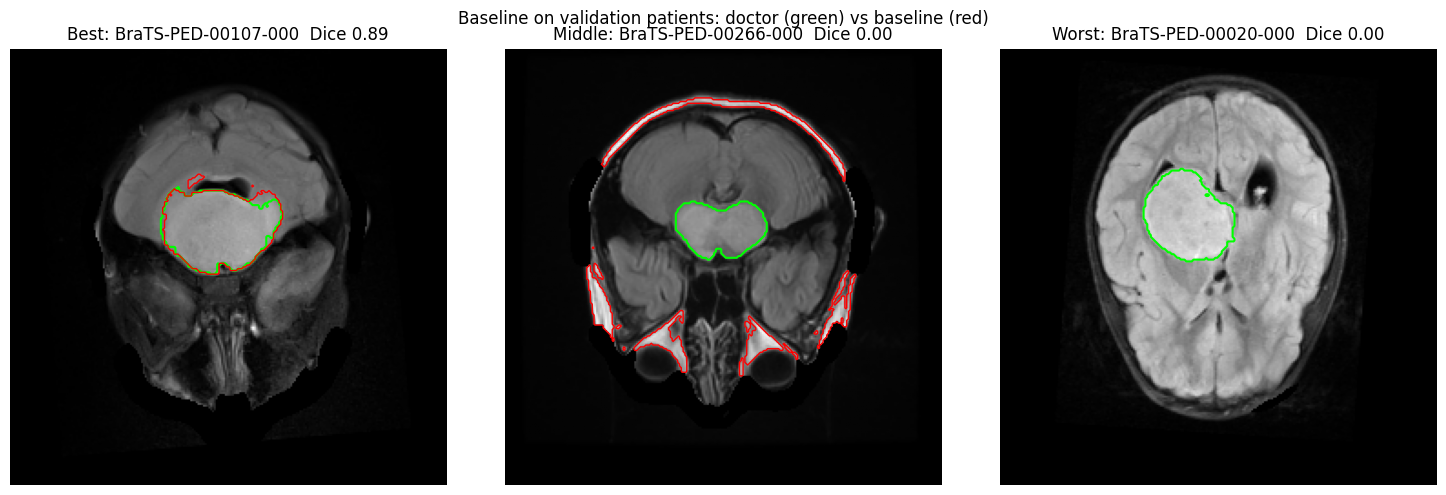

In [11]:
# CELL 7: picture check - doctor (green) vs baseline (red) on 3 validation patients
order = val_baseline.sort_values('dice_WT')
picks = [order.iloc[-1]['case'], order.iloc[len(order) // 2]['case'], order.iloc[0]['case']]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, cid, label in zip(axes, picks, ['Best', 'Middle', 'Worst']):
    flair, seg_i, _ = load_flair_seg(os.path.join(DATA_DIR, cid))
    ref = seg_i > 0
    pred = threshold_predict(zscore(flair), settings['threshold'], settings['keep_largest']) > 0
    z = int(np.argmax(ref.sum(axis=(0, 1))))
    ax.imshow(np.rot90(flair[:, :, z]), cmap='gray')
    ax.contour(np.rot90(ref[:, :, z]).astype(float), levels=[0.5], colors='lime', linewidths=1.5)
    if pred[:, :, z].any():
        ax.contour(np.rot90(pred[:, :, z]).astype(float), levels=[0.5], colors='red', linewidths=1)
    ax.set_title(f'{label}: {cid}  Dice {dice(pred, ref):.2f}')
    ax.axis('off')
fig.suptitle('Baseline on validation patients: doctor (green) vs baseline (red)')
plt.tight_layout()
plt.savefig(f'{WORK}/figures/baseline_val_outlines.png', dpi=200)
plt.show()

In [12]:
# CELL 8: random forest - collect example voxels from 60 training patients
N_FEATURES = 9

def make_features(seqs):
    feats = []
    for key in ['t1n', 't1c', 't2w', 't2f']:
        z = zscore(seqs[key])
        feats.append(z)                                    # brightness of the voxel
        feats.append(ndimage.uniform_filter(z, size=5))    # average brightness of its 5x5x5 neighbourhood
    head = seqs['t2f'] > 0
    feats.append(ndimage.distance_transform_edt(head))     # distance (mm) from the edge of the head: scalp ~0, tumours deep inside
    return np.stack(feats, axis=-1).astype(np.float32)     # shape (240, 240, 155, 9)

rng = np.random.default_rng(42)
N_TUMOUR = 2000    # voxels per tumour label (1-4) per patient
N_BG = 10000       # background voxels per patient (includes scalp, so the forest learns scalp is not tumour)
rf_patients = rng.choice(train_ids, size=60, replace=False)   # 60 of the 179 training patients
X_parts, y_parts = [], []
for i, cid in enumerate(rf_patients, 1):
    seqs_i, seg_i, _ = load_case(os.path.join(DATA_DIR, cid))
    F = make_features(seqs_i).reshape(-1, N_FEATURES)
    labels = seg_i.ravel()
    head = (seqs_i['t2f'] > 0).ravel()
    for label in [0, 1, 2, 3, 4]:
        idx = np.flatnonzero((labels == label) & head)
        if idx.size == 0:
            continue                                       # this patient has none of this label
        n = min(N_BG if label == 0 else N_TUMOUR, idx.size)
        pick = rng.choice(idx, size=n, replace=False)
        X_parts.append(F[pick])
        y_parts.append(labels[pick])
    print(f'{i}/60 {cid}')

X = np.concatenate(X_parts)
y = np.concatenate(y_parts)
print(X.shape, '| voxels per label 0-4:', np.bincount(y, minlength=5))
np.savez_compressed(f'{WORK}/models/rf_training_voxels.npz', X=X, y=y)
print('Saved training voxels to Drive')

1/60 BraTS-PED-00139-000
2/60 BraTS-PED-00016-000
3/60 BraTS-PED-00064-000
4/60 BraTS-PED-00254-000
5/60 BraTS-PED-00172-000
6/60 BraTS-PED-00199-000
7/60 BraTS-PED-00176-000
8/60 BraTS-PED-00187-000
9/60 BraTS-PED-00097-000
10/60 BraTS-PED-00102-000
11/60 BraTS-PED-00239-000
12/60 BraTS-PED-00203-000
13/60 BraTS-PED-00042-000
14/60 BraTS-PED-00085-000
15/60 BraTS-PED-00193-000
16/60 BraTS-PED-00144-000
17/60 BraTS-PED-00017-000
18/60 BraTS-PED-00019-000
19/60 BraTS-PED-00128-000
20/60 BraTS-PED-00101-000
21/60 BraTS-PED-00121-000
22/60 BraTS-PED-00263-000
23/60 BraTS-PED-00159-000
24/60 BraTS-PED-00160-000
25/60 BraTS-PED-00134-000
26/60 BraTS-PED-00044-000
27/60 BraTS-PED-00024-000
28/60 BraTS-PED-00123-000
29/60 BraTS-PED-00185-000
30/60 BraTS-PED-00148-000
31/60 BraTS-PED-00220-000
32/60 BraTS-PED-00207-000
33/60 BraTS-PED-00100-000
34/60 BraTS-PED-00051-000
35/60 BraTS-PED-00170-000
36/60 BraTS-PED-00226-000
37/60 BraTS-PED-00099-000
38/60 BraTS-PED-00109-000
39/60 BraTS-PED-00132

In [13]:
# CELL 9: train the random forest, save it, and show which clues it relied on
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=50, max_depth=12, min_samples_leaf=20,
                            n_jobs=-1, random_state=42)
rf.fit(X, y)
path = f'{WORK}/models/rf_model.joblib'
joblib.dump(rf, path, compress=3)
print('Saved model. File size (MB):', round(os.path.getsize(path) / 1e6, 1))

names = [f'{k} {t}' for k in ['t1n', 't1c', 't2w', 't2f'] for t in ['voxel', 'neighbourhood']] + ['distance from head edge']
print('\nWhich clues the forest relied on most:')
for n, imp in sorted(zip(names, rf.feature_importances_), key=lambda x: -x[1]):
    print(f'  {n:26s} {imp:.3f}')

Saved model. File size (MB): 6.5

Which clues the forest relied on most:
  t2f neighbourhood          0.314
  t2w neighbourhood          0.169
  t2f voxel                  0.136
  t2w voxel                  0.086
  distance from head edge    0.082
  t1c voxel                  0.060
  t1n voxel                  0.057
  t1c neighbourhood          0.049
  t1n neighbourhood          0.047


In [14]:
# CELL 10: random forest on the 39 validation patients (all tumour parts)
def rf_predict_case(rf, seqs, chunk=300_000):
    shape = seqs['t2f'].shape
    F = make_features(seqs).reshape(-1, N_FEATURES)
    head = (seqs['t2f'] > 0).ravel()
    pred = np.zeros(head.size, dtype=np.uint8)
    idx = np.flatnonzero(head)
    for s in range(0, idx.size, chunk):                 # in chunks so memory doesn't run out
        part = idx[s:s + chunk]
        pred[part] = rf.predict(F[part])
    return pred.reshape(shape)

rf = joblib.load(f'{WORK}/models/rf_model.joblib')
rows = []
for i, cid in enumerate(val_ids, 1):
    seqs_i, seg_i, spacing_i = load_case(os.path.join(DATA_DIR, cid))
    pred = rf_predict_case(rf, seqs_i)
    rows.append({'case': cid, **score_case(pred, seg_i, spacing_i)})
    print(f'{i}/{len(val_ids)} {cid}  WT Dice {rows[-1]["dice_WT"]:.2f}')

val_rf = pd.DataFrame(rows)
val_rf.to_csv(f'{WORK}/results/rf_val.csv', index=False)

print('\nValidation results (mean Dice | median Dice | mean HD95 mm):')
for r in ['WT', 'TC', 'ET', 'NET', 'CC', 'ED']:
    print(f"  {r:4s} {val_rf[f'dice_{r}'].mean():.3f} | {val_rf[f'dice_{r}'].median():.3f} | {val_rf[f'hd95_{r}'].mean():.1f}")
print('\nWhole tumour, baseline vs forest (mean Dice):',
      round(val_baseline['dice_WT'].mean(), 3), 'vs', round(val_rf['dice_WT'].mean(), 3))

1/39 BraTS-PED-00008-000  WT Dice 0.31
2/39 BraTS-PED-00010-000  WT Dice 0.71
3/39 BraTS-PED-00020-000  WT Dice 0.56
4/39 BraTS-PED-00027-000  WT Dice 0.18
5/39 BraTS-PED-00031-000  WT Dice 0.66
6/39 BraTS-PED-00033-000  WT Dice 0.73
7/39 BraTS-PED-00035-000  WT Dice 0.55
8/39 BraTS-PED-00043-000  WT Dice 0.82
9/39 BraTS-PED-00053-000  WT Dice 0.06
10/39 BraTS-PED-00059-000  WT Dice 0.14
11/39 BraTS-PED-00072-000  WT Dice 0.46
12/39 BraTS-PED-00074-000  WT Dice 0.27
13/39 BraTS-PED-00075-000  WT Dice 0.10
14/39 BraTS-PED-00104-000  WT Dice 0.10
15/39 BraTS-PED-00107-000  WT Dice 0.54
16/39 BraTS-PED-00114-000  WT Dice 0.23
17/39 BraTS-PED-00115-000  WT Dice 0.30
18/39 BraTS-PED-00116-000  WT Dice 0.22
19/39 BraTS-PED-00143-000  WT Dice 0.43
20/39 BraTS-PED-00149-000  WT Dice 0.06
21/39 BraTS-PED-00152-000  WT Dice 0.03
22/39 BraTS-PED-00156-000  WT Dice 0.20
23/39 BraTS-PED-00163-000  WT Dice 0.45
24/39 BraTS-PED-00168-000  WT Dice 0.32
25/39 BraTS-PED-00171-000  WT Dice 0.85
26/39 Bra